# Análisis del espectro de la fuente de neutrones $^{241}$Am-Be (entrada de MEIGA)

Revisión de la carpeta `Simulacion-fuente-241AmBe` (los archivos originales no se modifican). El informe completo está en `informe/Informe-fuente-AmBe241.pdf`.

**Cadena original** (`simulacion-241-AmBe.ipynb`): puntos digitalizados $(E_i,y_i)$ → $n_i=\mathrm{round}(|y_i|\cdot2.5\times10^6)$ → cada $E_i$ repetida $n_i$ veces → $p_z=\sqrt{(T+m_n)^2-m_n^2}$ en GeV/c → `13 0 0 pz 0 0 0 0 0 0 0 0` (1 637 458 neutrones).

## 1. Diagnóstico, espectro limpio y fuente original
`scripts/analizar_fuente.py` escribe `resultados/resumen.json` y las figuras 1–7.

In [1]:
import runpy, json
runpy.run_path('scripts/analizar_fuente.py', run_name='__main__');

{
 "digitalizacion": {
  "puntos": 667,
  "energias_distintas": 437,
  "pasos_hacia_atras_en_E": 193,
  "pares_repetidos_exactos": 4,
  "valores_negativos": 3,
  "E_min": 0.10327022375215167,
  "E_max": 10.895008605851979,
  "puntos_espurios": 28,
  "peso_espurio_pct": 6.174207848251923,
  "indices_espurios": [
   0,
   146,
   148,
   149,
   154,
   179,
   180,
   182,
   184,
   235,
   296,
   298,
   299,
   327,
   363,
   364,
   450,
   451,
   452,
   453,
   484,
   485,
   486,
   650,
   651,
   652,
   653,
   654
  ]
 },
 "espectro_limpio": {
  "E_media_MeV": 4.152336522574526,
  "E_mediana_MeV": 3.985789908007624,
  "E_moda_MeV": 3.0250000000000004,
  "E_rms_MeV": 4.819759502170633,
  "picos_MeV": [
   3.03,
   4.88,
   6.33,
   7.47,
   9.53
  ],
  "fraccion_bandas_pct": {
   "0.1-1": 12.08,
   "1-2": 9.6,
   "2-4": 28.51,
   "4-6": 26.23,
   "6-8": 16.89,
   "8-11": 6.69
  }
 },
 "fuente_meiga": {
  "archivo": "Espectro-completo-neutrones-fuente-AmBe241.txt",
  "neutr

### Digitalización principal
667 puntos, no ordenados en $E$ (193 pasos hacia atrás, 437 energías distintas), 28 puntos espurios (6.2 % de los neutrones de la fuente) y 3 valores negativos convertidos con `abs`.

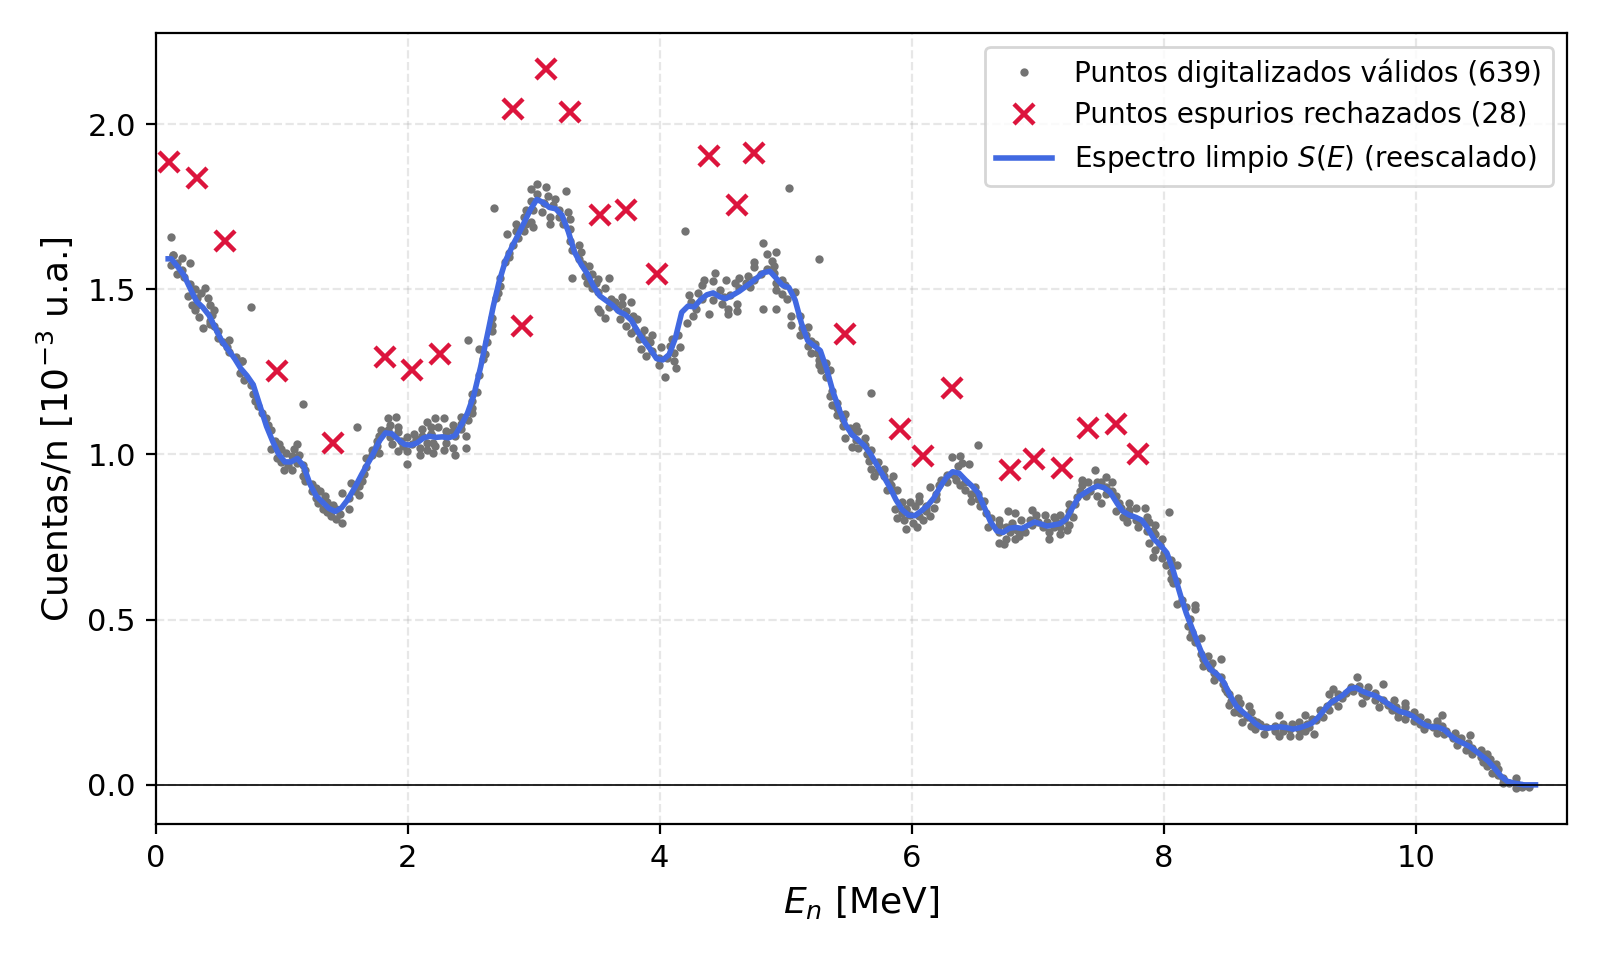

In [2]:
from IPython.display import Image
Image('figuras/fig01_digitalizacion_espurios.png', width=780)

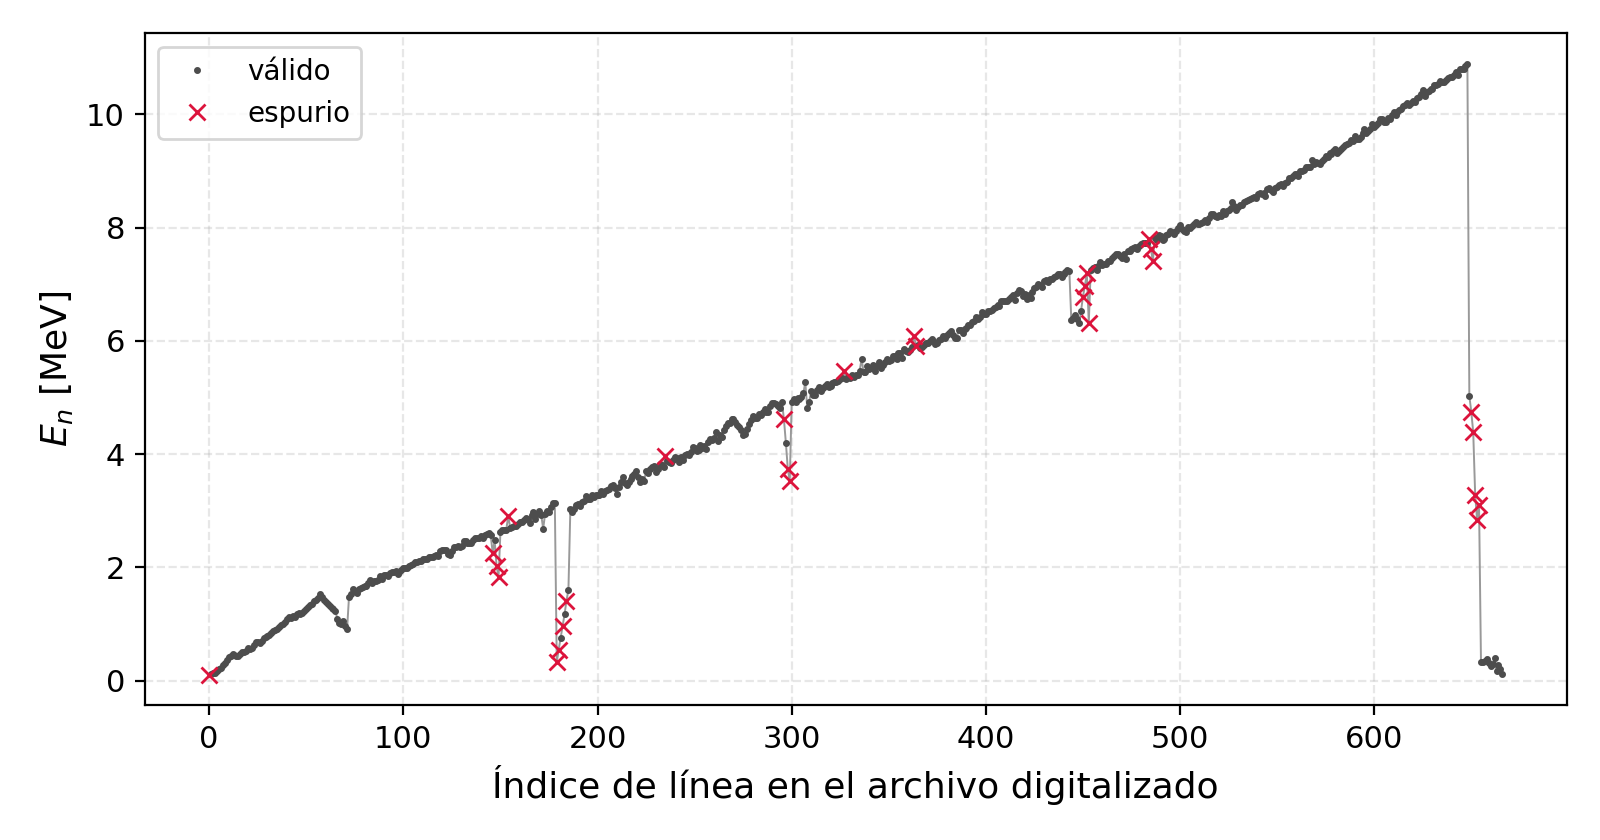

In [3]:
from IPython.display import Image
Image('figuras/fig02_orden_digitalizacion.png', width=780)

### Espectro limpio
$\langle E\rangle = 4.15$ MeV (ISO 8529-1: 4.16 MeV), máximos en 3.03, 4.88, 6.33, 7.47 y 9.53 MeV. Archivo: `resultados/espectro_AmBe_limpio.txt`.

> La procedencia de la figura digitalizada no está registrada en la carpeta: hay que citarla en la tesis.

### Sesgo por densidad de puntos
El notebook asigna $n_i\propto y_i$ a *cada punto*; el número correcto es $\propto S(E)\,\Delta E$. La razón fuente/limpio (0.54–1.35 por bin de 0.25 MeV) sigue al número de puntos por bin (correlación 0.97); por encima de 8 MeV faltan un 17 % de neutrones y $\langle E\rangle$ queda en 4.06 MeV.

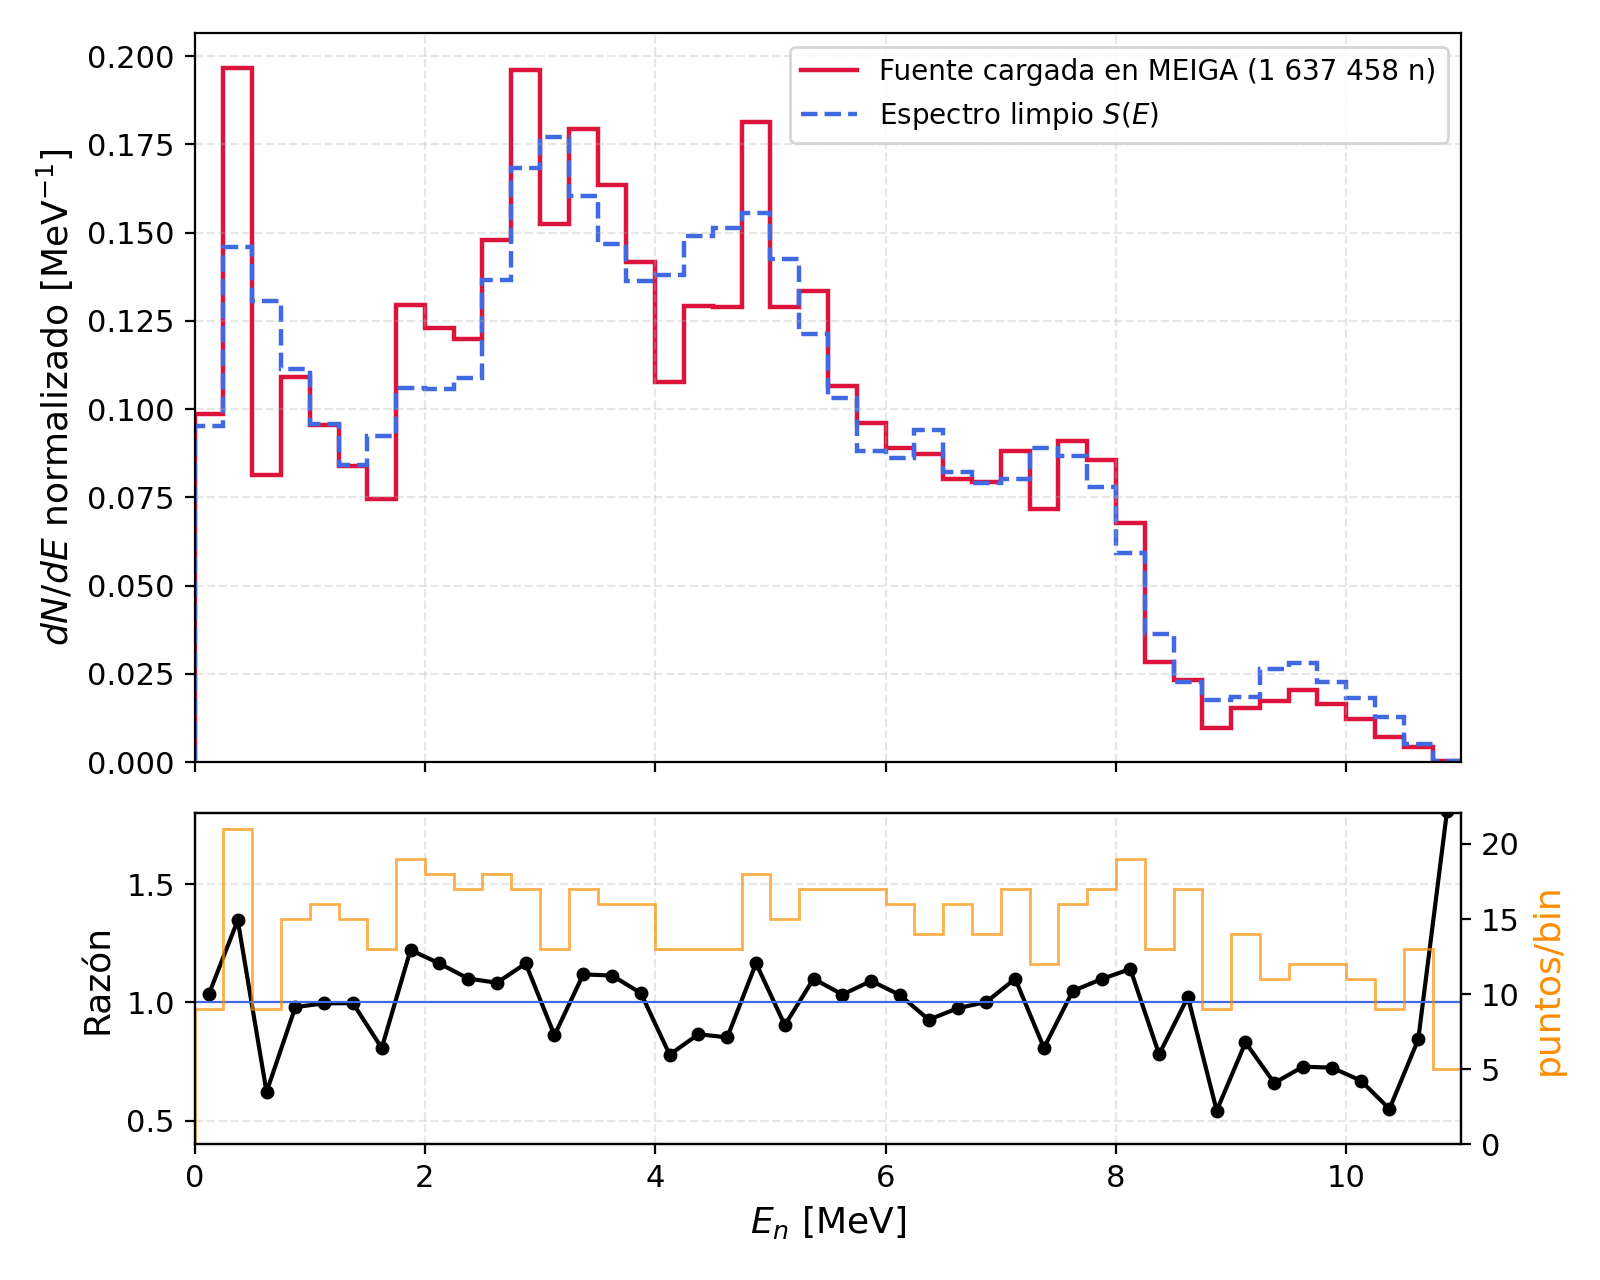

In [4]:
from IPython.display import Image
Image('figuras/fig03_fuente_vs_limpio.png', width=780)

### Espectro discreto
La fuente es un peine de 437 energías: los picos de las figuras *Geant4 (suavizado)* son este artefacto. Además, esa curva es el archivo de **entrada**, no una salida de Geant4.

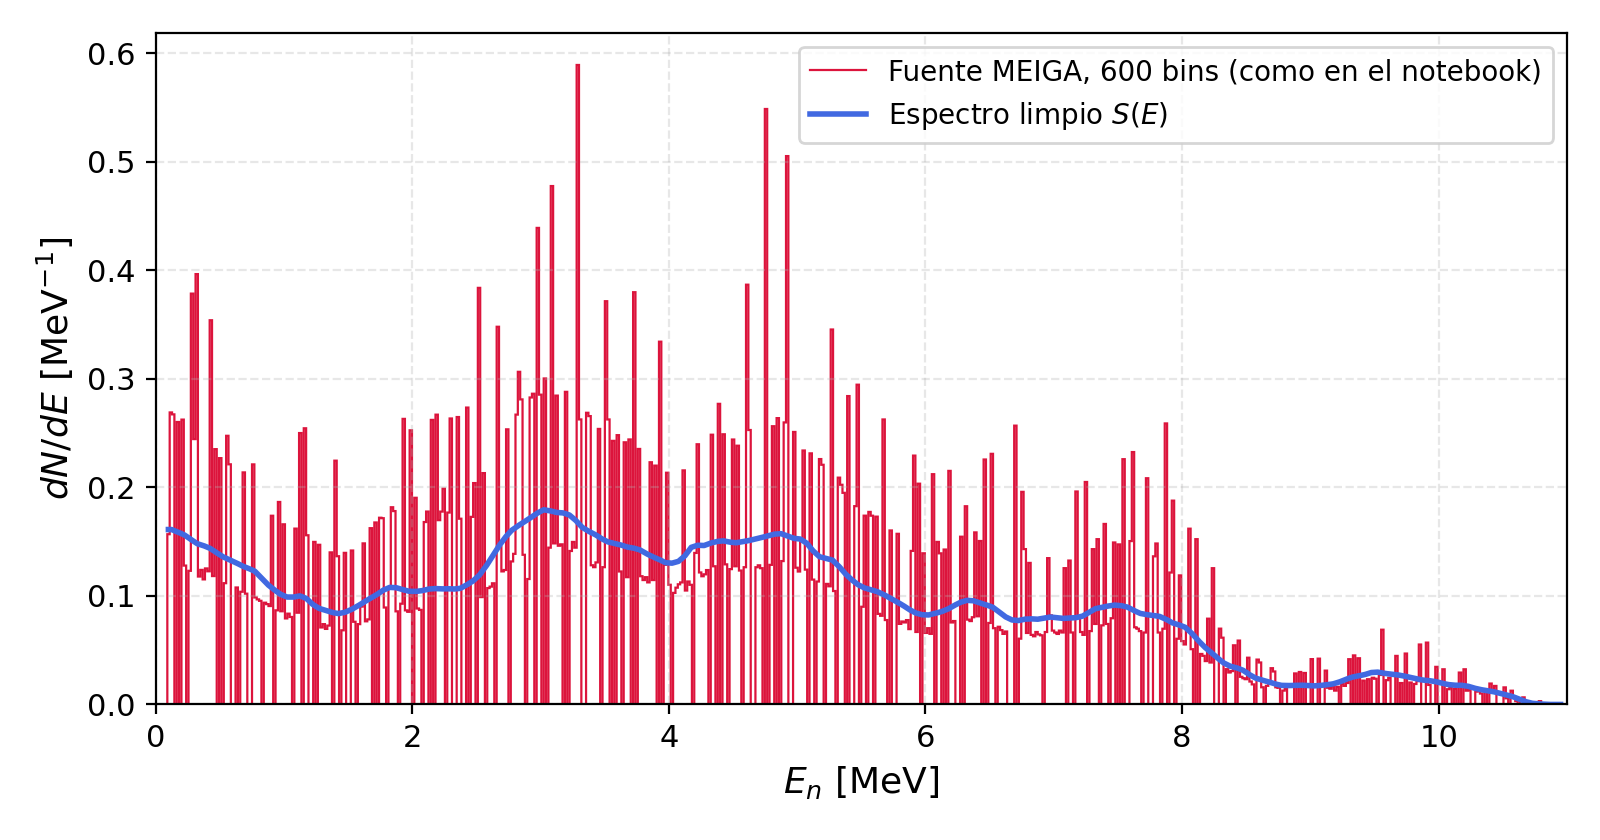

In [5]:
from IPython.display import Image
Image('figuras/fig04_fuente_discreta.png', width=780)

### Orden del archivo
Los neutrones están en el orden de la digitalización: el primer 1 % tiene $\langle E\rangle=0.12$ MeV, el primer 50 % llega solo a 4.17 MeV. **Verificar si alguna corrida usó solo parte del archivo.** Dirección: todos en $+z$ (haz pincel).

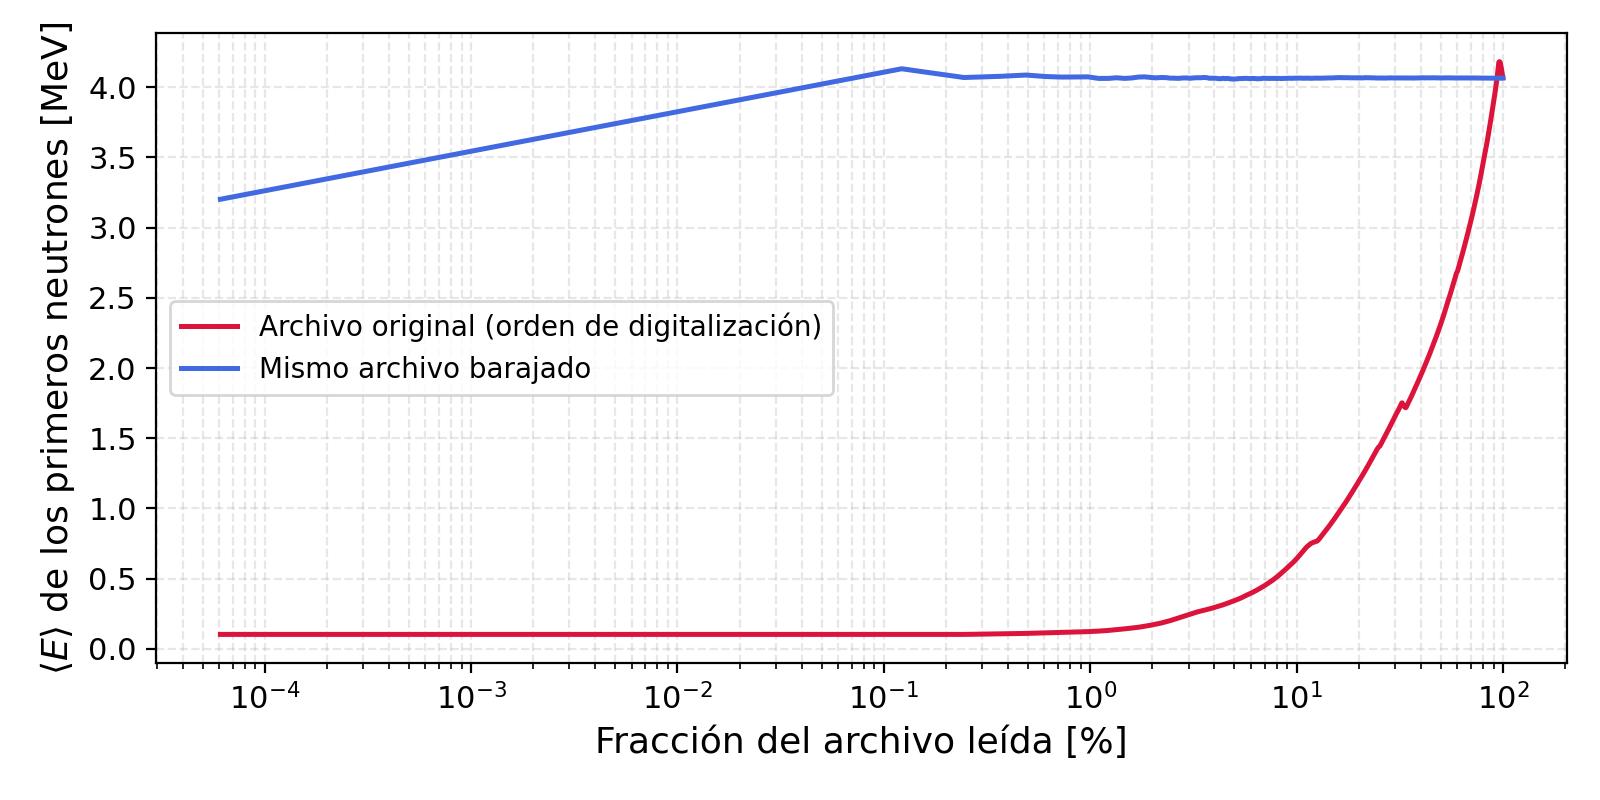

In [6]:
from IPython.display import Image
Image('figuras/fig07_sesgo_orden.png', width=780)

## 2. Segunda digitalización (eje $y$ invertido)
Correlación con $S(E)$ = −0.997. Invertir el orden de la columna (`col2[::-1]`, `Funcion-espectro-AmBe-241-final.txt`) refleja el espectro en energía y **no** lo corrige (correlación 0.32); lo correcto es $y'=(a-y)/|b|$.

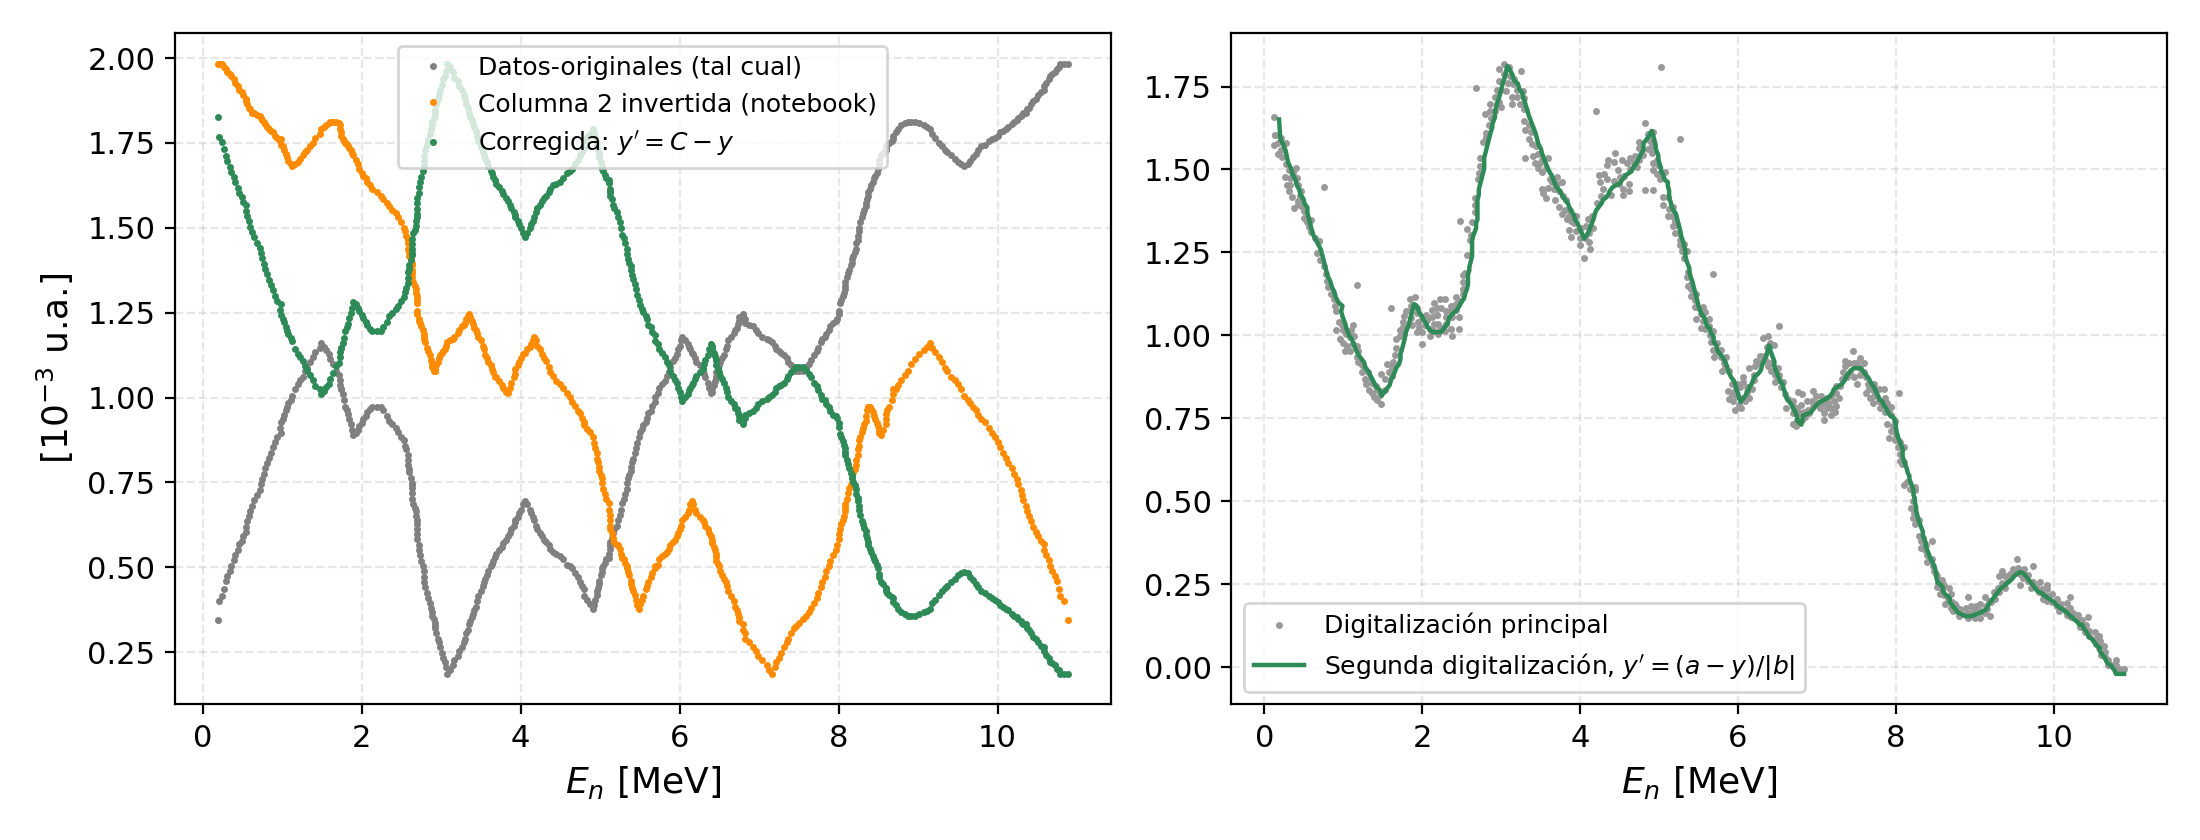

In [7]:
from IPython.display import Image
Image('figuras/fig05_segunda_digitalizacion.png', width=780)

## 3. Curvas de referencia
`AmBe_IAEA.txt` es un triángulo de valores redondos (máximo único en 3.5 MeV), no un espectro IAEA/ISO; `AmBe_ISO8529_spectrum.txt` y `AmBe_neutron_spectrum.txt` son curvas analíticas con $\langle E\rangle$ = 3.47 y 2.22 MeV, tampoco ISO 8529-1.

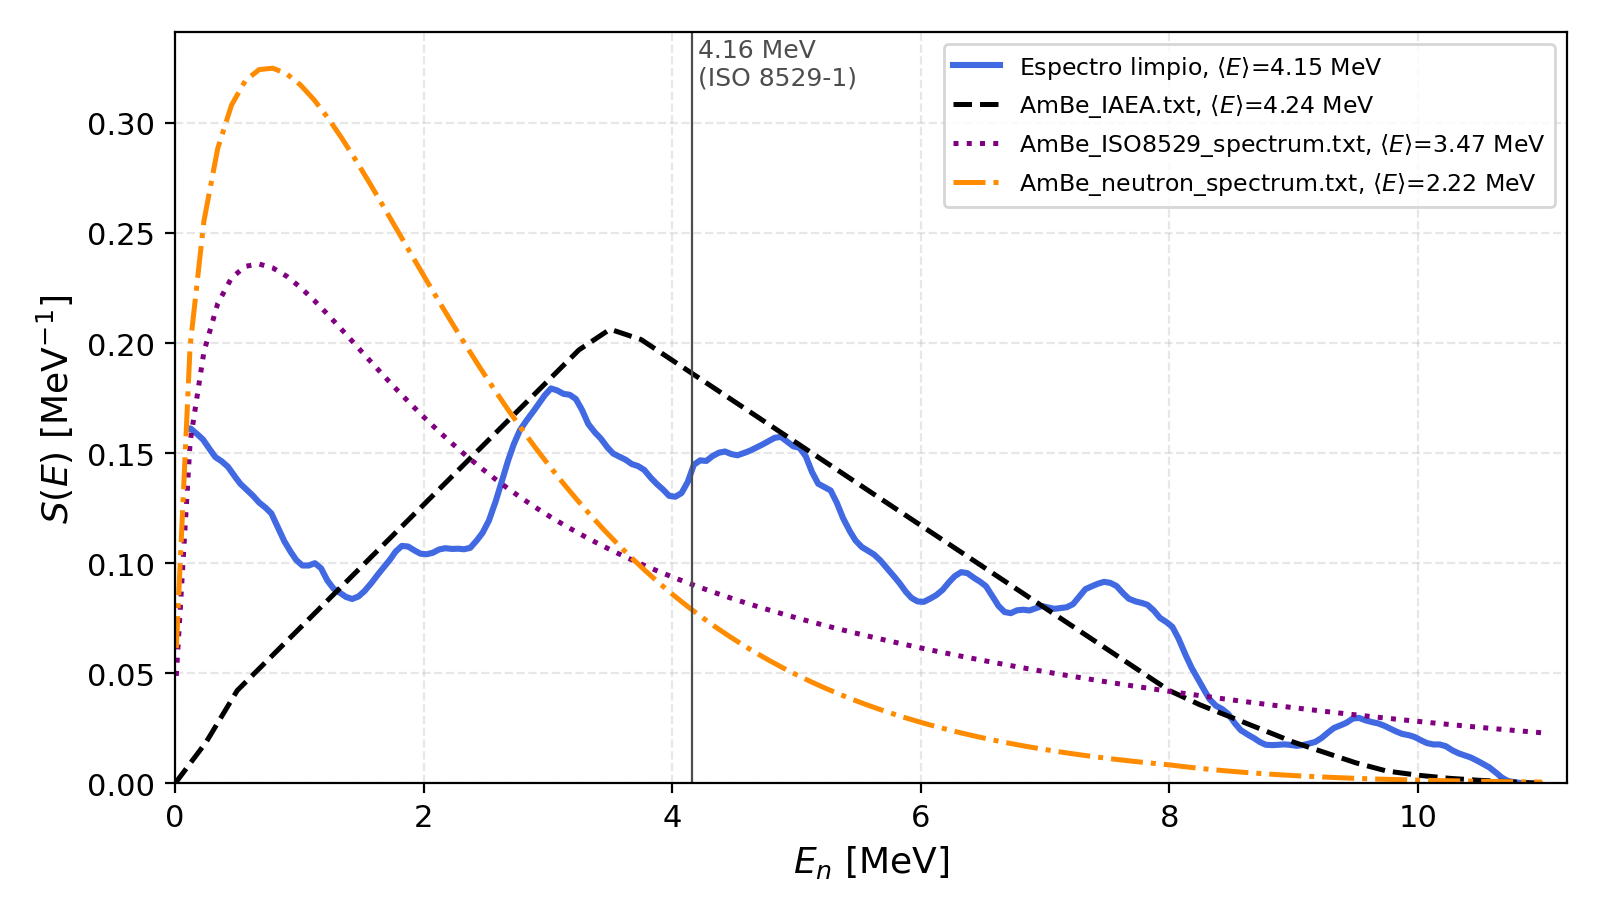

In [8]:
from IPython.display import Image
Image('figuras/fig06_referencias.png', width=780)

## 4. Fuente corregida
`scripts/generar_fuente.py` muestrea $S(E)$ (energías continuas, orden aleatorio, mismo formato). Opciones: `-n`, `--semilla`, `--direccion +z|-z|+x|iso`. Se omite si el archivo ya existe.

In [9]:
import os, subprocess, sys
f = 'resultados/Fuente-AmBe241-corregida-1637458n.txt'
if not os.path.exists(f):
    subprocess.run([sys.executable, 'scripts/generar_fuente.py'], check=True)
runpy.run_path('scripts/validar_fuente.py', run_name='__main__');

{
 "archivo": "Fuente-AmBe241-corregida-1637458n.txt",
 "neutrones": 1637458,
 "ids": [
  13
 ],
 "E_media_MeV": 4.151099567259839,
 "E_media_esperada_MeV": 4.152336527503975,
 "E_media_original_MeV": 4.0642774652529265,
 "chi2": 218.04748793407742,
 "ndf": 214,
 "chi2_ndf": 1.0189134950190535,
 "energias_distintas": 1311568,
 "E_media_primer_1pct": 4.171397844836036,
 "E_media_primer_10pct": 4.140629524754865
}


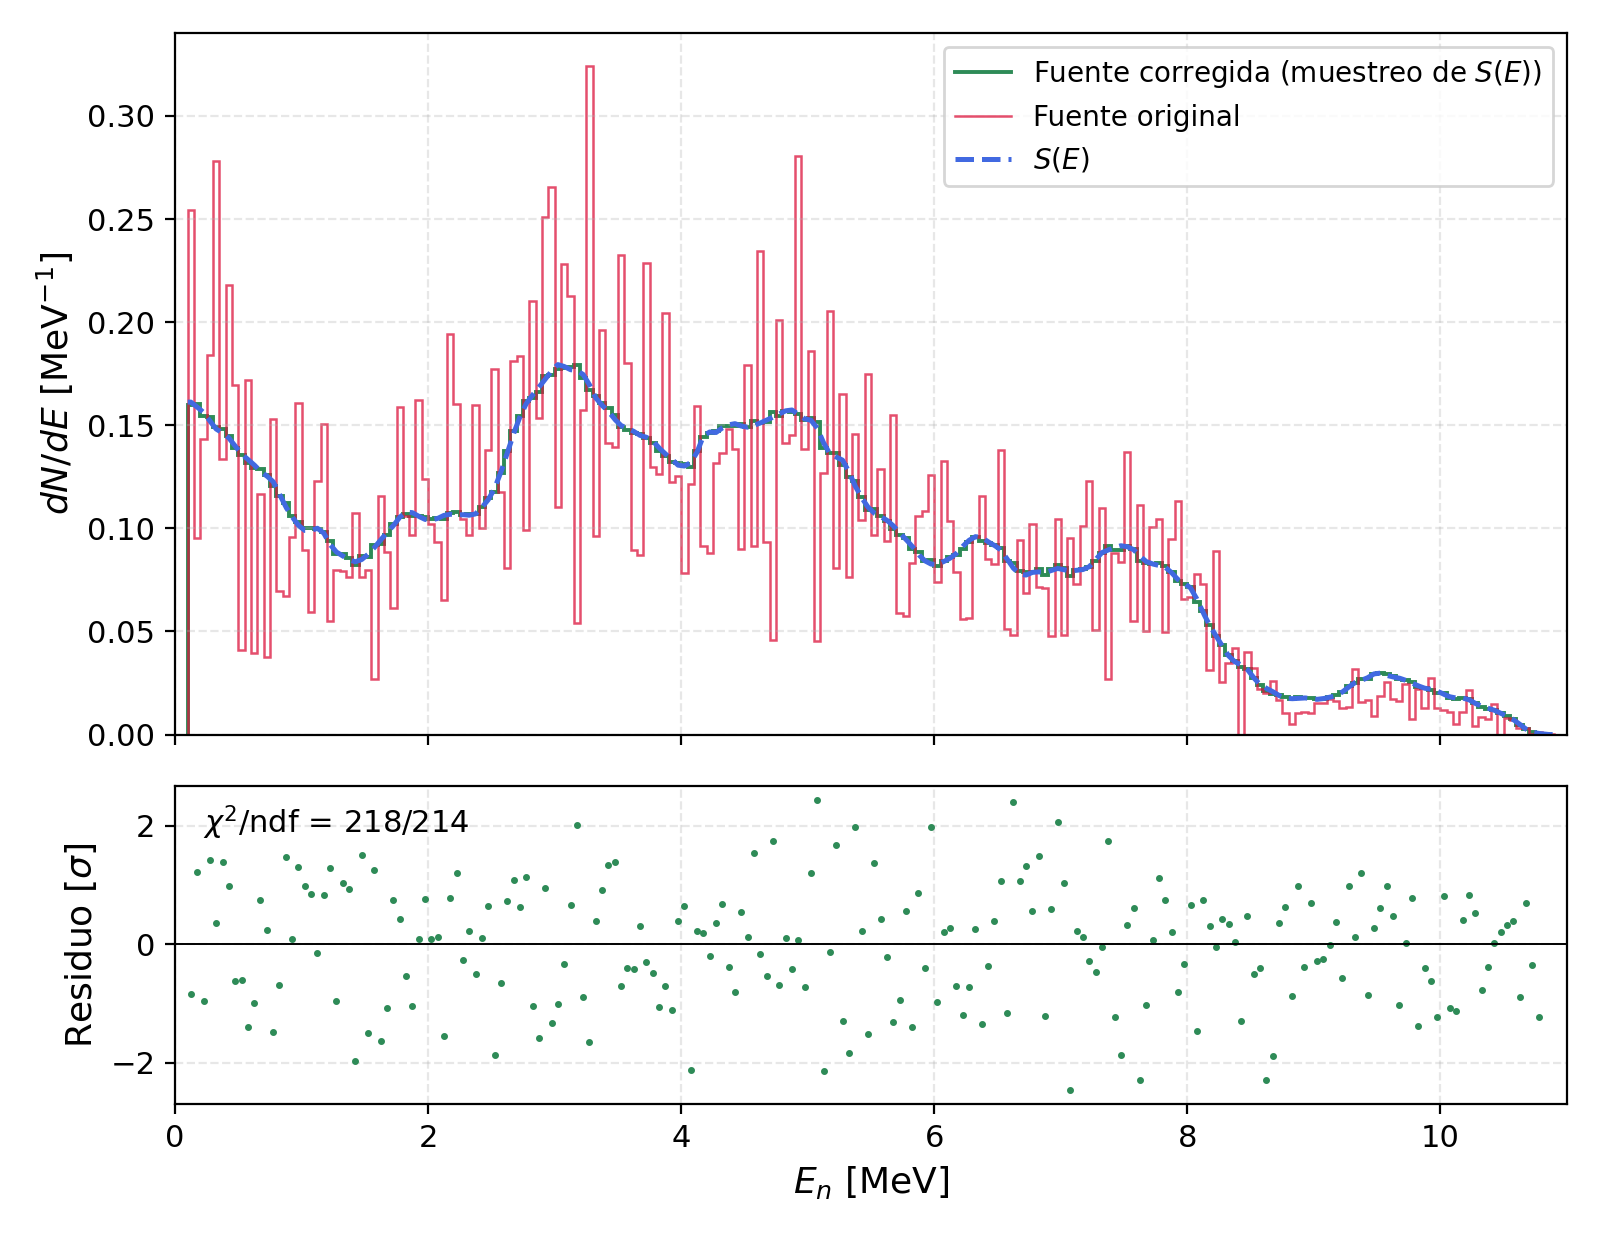

In [10]:
from IPython.display import Image
Image('figuras/fig08_validacion_fuente_corregida.png', width=780)

## 5. Espectro de referencia ISO 8529 digitalizado
Figura ISO 8529 del espectro $^{241}$Am-Be ($B_E\cdot E$ frente a $E$ en escala log) tomada de la lámina 26 de la presentación IAEA *Establishing neutron calibrations at SSDL using ISO 8529 radionuclide sources* (imagen en `referencia_ISO8529/`). `scripts/digitalizar_iso8529.py` la digitaliza por píxeles (47 grupos, 0.1–10.84 MeV): calibración $y$ lineal con las marcas del eje y $x$ interpolando $\log_{10}E$ entre todas las marcas, porque las décadas del dibujo tienen anchos distintos. Los escalones más angostos que el trazo se recuperan intersectando los intervalos de las columnas vecinas.

$\langle E\rangle$ = 4.21 MeV (ISO 8529-1:2021: 4.17 MeV para fuente pequeña). La digitalización previa de la carpeta coincide con este espectro (fracciones por banda iguales con diferencias de ≈1 punto porcentual): era el espectro ISO.

In [11]:
runpy.run_path('scripts/digitalizar_iso8529.py', run_name='__main__');
runpy.run_path('scripts/comparar_iso8529.py', run_name='__main__');

47 grupos, E de 0.1000 a 10.839 MeV, <E> = 4.211 MeV


{
 "E_media_ISO_digitalizado_MeV": 4.2108641103402205,
 "E_media_ISO_8529_1_2001_MeV": 4.16,
 "E_media_ISO_8529_1_2021_pequena_MeV": 4.17,
 "E_media_ISO_8529_1_2021_grande_MeV": 4.05,
 "E_media_digitalizacion_previa_limpia_MeV": 4.152336527503975,
 "grupos": 47,
 "fraccion_bandas_pct": {
  "0.1-1": {
   "ISO": 12.57,
   "previa": 12.08
  },
  "1-2": {
   "ISO": 9.4,
   "previa": 9.6
  },
  "2-4": {
   "ISO": 27.4,
   "previa": 28.51
  },
  "4-6": {
   "ISO": 26.09,
   "previa": 26.23
  },
  "6-8": {
   "ISO": 16.87,
   "previa": 16.89
  },
  "8-11": {
   "ISO": 7.66,
   "previa": 6.69
  }
 }
}


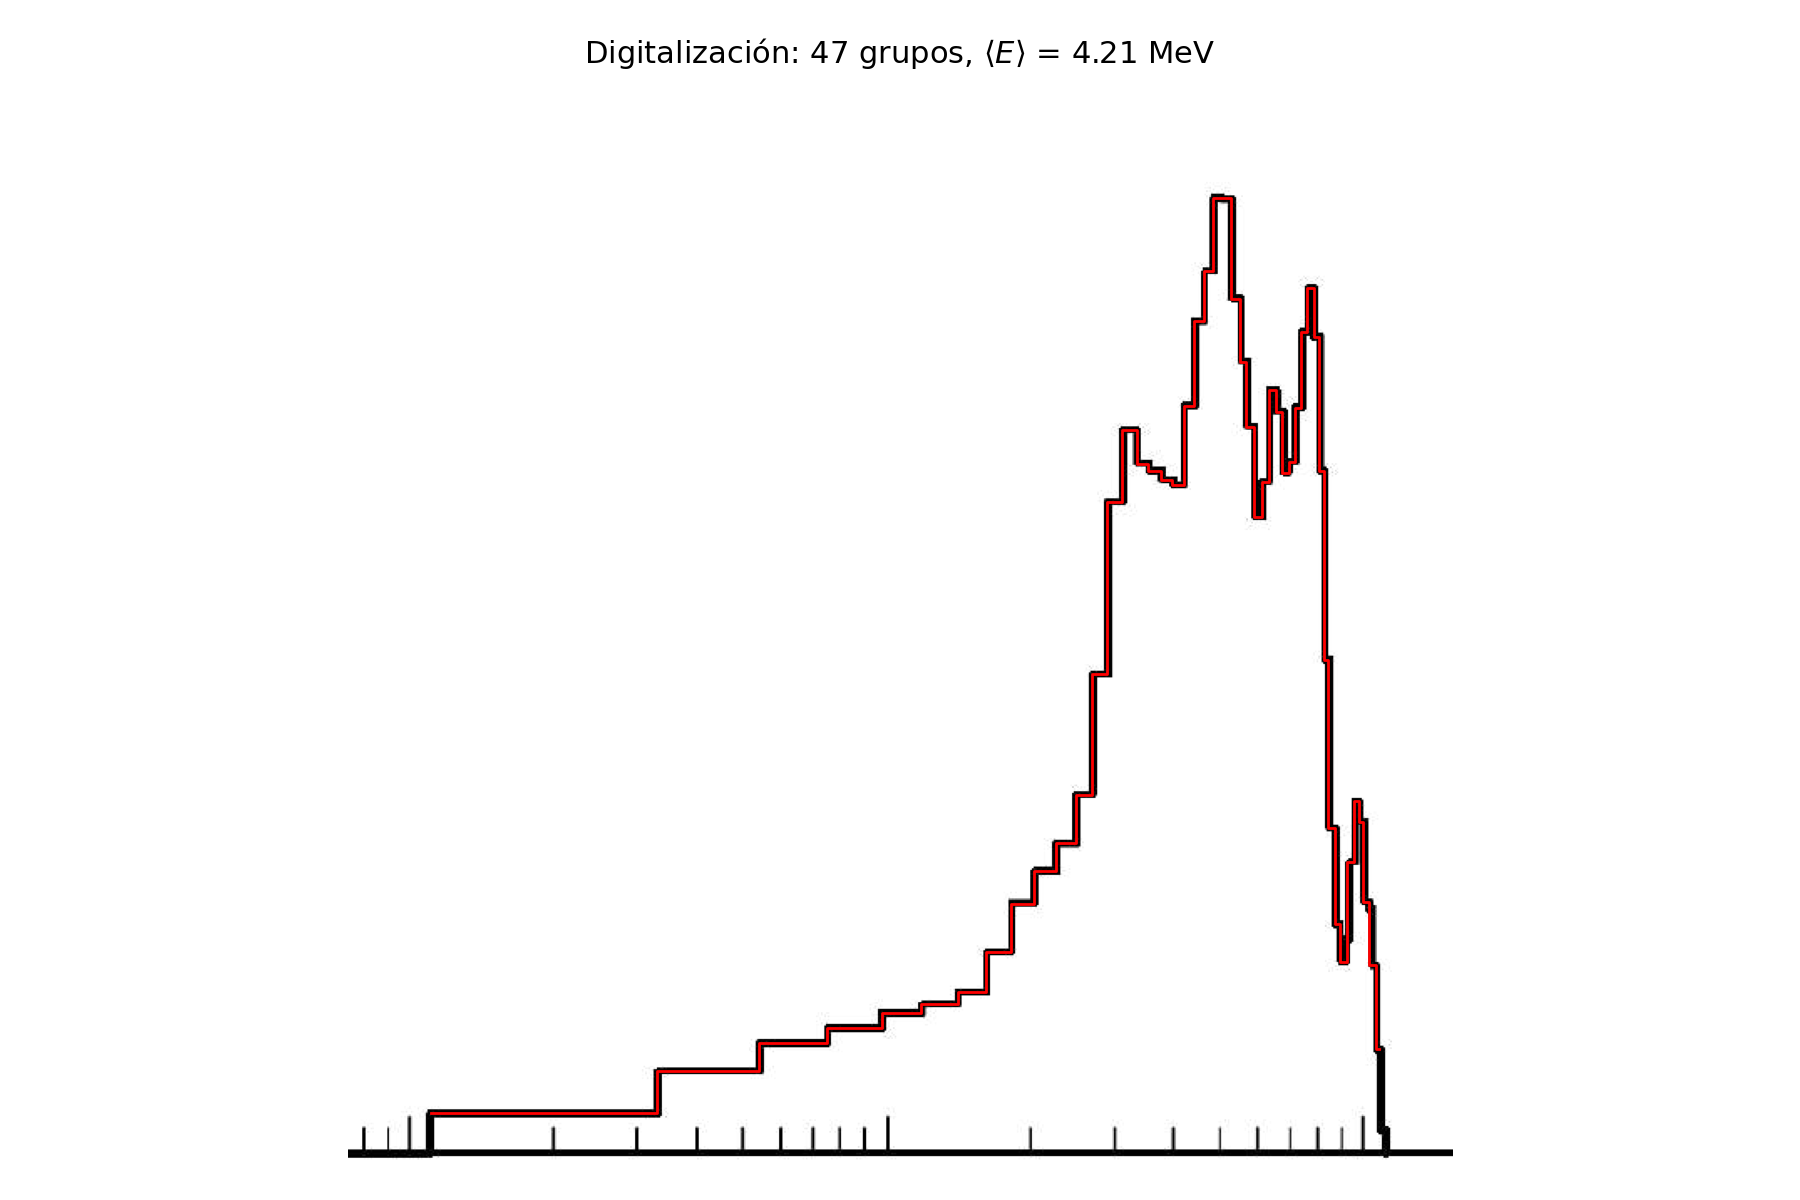

In [12]:
from IPython.display import Image
Image('figuras/fig09_digitalizacion_ISO8529.png', width=780)

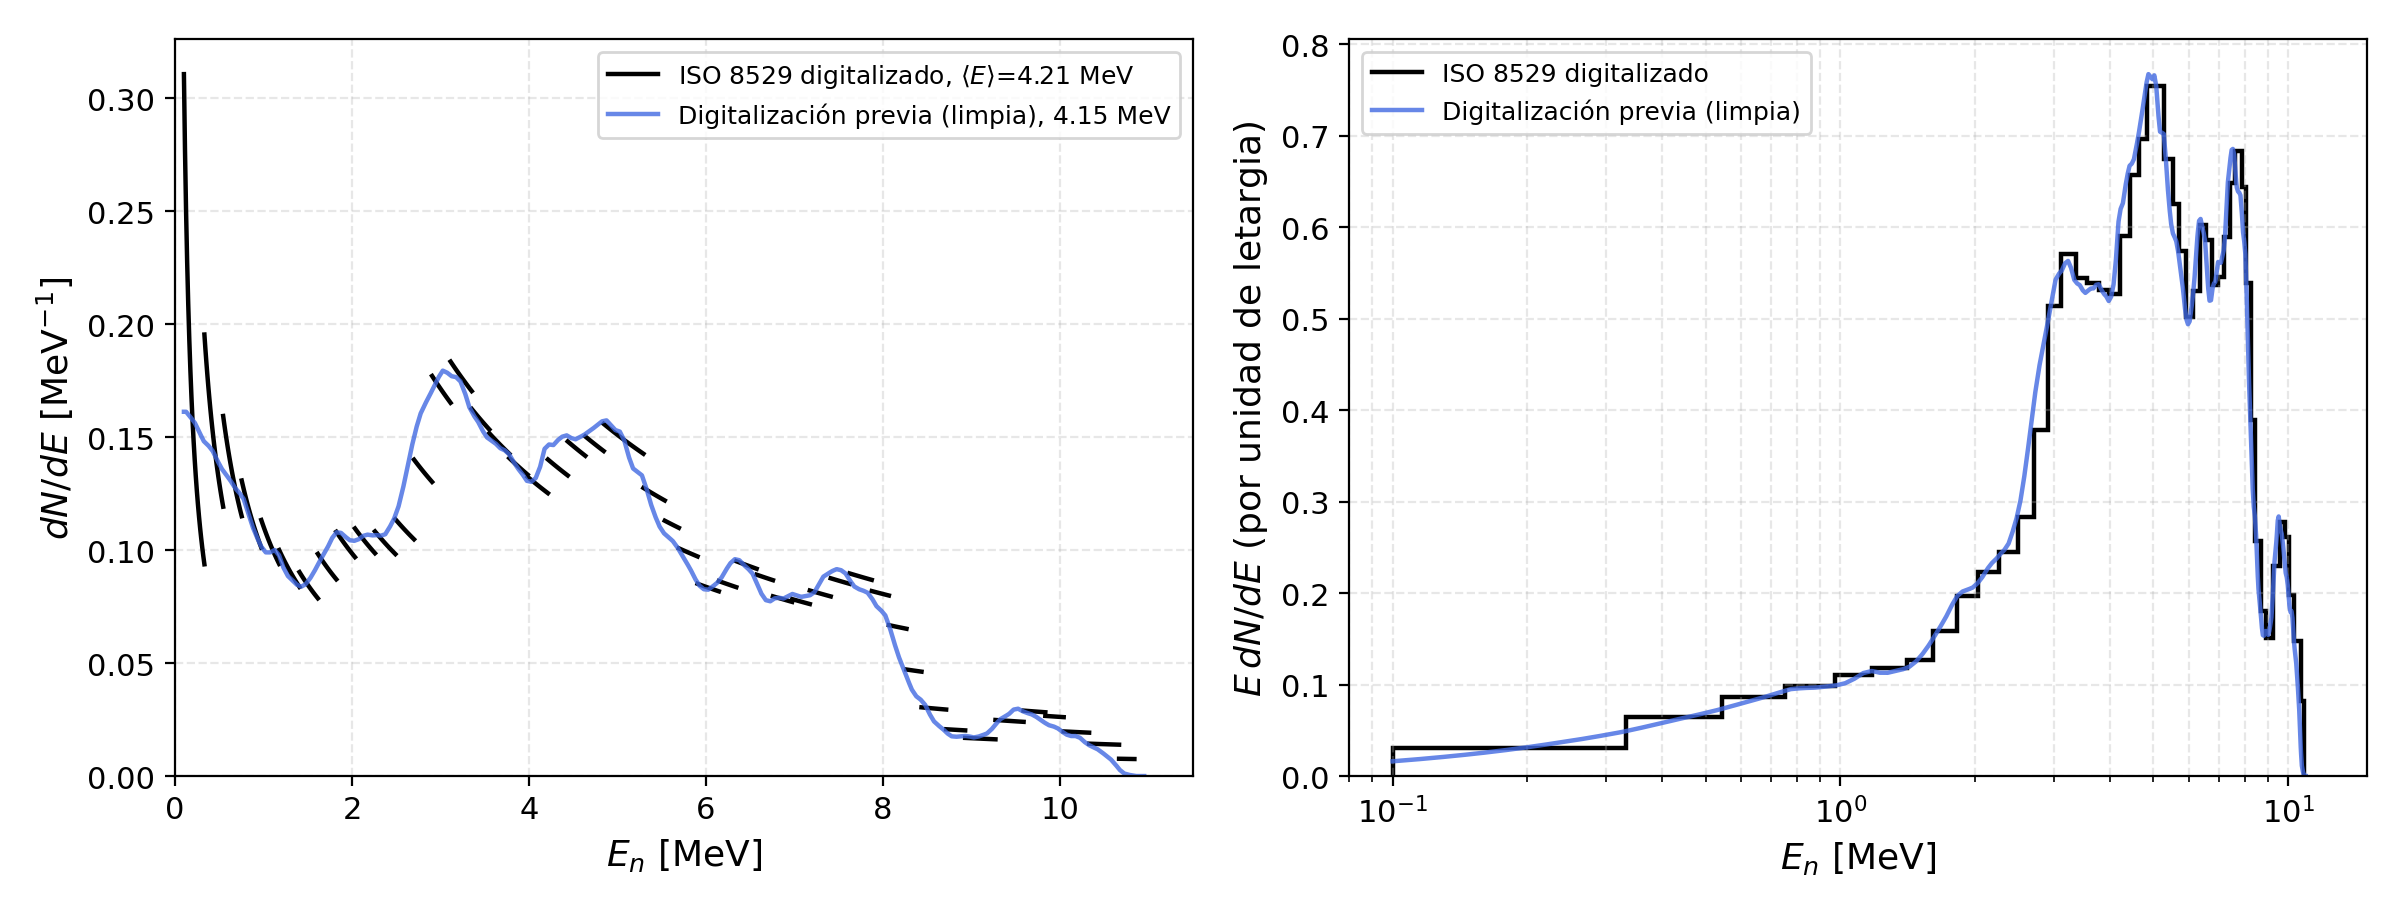

In [13]:
from IPython.display import Image
Image('figuras/fig10_iso8529_vs_previa.png', width=780)

## 6. Irradiación del tanque: 1 Ci durante 5 minutos, fuente a 10 cm
`scripts/generar_irradiacion.py`: $Q = 3.7\times10^{10}$ Bq × $6\times10^{-5}$ n s$^{-1}$Bq$^{-1}$ = $2.22\times10^6$ n/s (ISO 8529-1:2021, valor indicativo); $N\sim$ Poisson($Q\cdot300$ s). Fuente puntual isótropa en $(-58.062, 0, 66.562)$ cm: 10 cm fuera de la pared exterior ($R_{ext}$ = 48.062 cm) y a media altura del agua. Solo se escriben los neutrones cuya dirección corta el tanque, en archivos de $10^6$ líneas, formato `13 px py pz x y z 0 0 0 0 0` con **pz invertido** (MEIGA usa $-p_z$) y `injectionMode eFromFile` (ver `configuracion/DetectorList-AmBe-d10cm.xml`). Cada parte es una muestra aleatoria del total.

In [14]:
import json
r = json.load(open('resultados/Irradiacion-AmBe-1Ci-300s-d10cm/resumen.json'))
{k: v for k, v in r.items() if not k.startswith('hist')}

{'actividad_Ci': 1.0,
 'actividad_Bq': 37000000000.0,
 'rendimiento_n_por_s_Bq': 6e-05,
 'Q_n_por_s': 2220000.0,
 'tiempo_s': 300.0,
 'neutrones_emitidos_4pi': 665980683,
 'neutrones_hacia_el_tanque': 202363865,
 'fraccion_geometrica': 0.3038584604112309,
 'error_fraccion': 1.7821884508233737e-05,
 'tasa_al_tanque_n_por_s': 674546.2166666667,
 'fuente_cm': [-58.062, 0.0, 66.562],
 'd_pared_cm': 10.0,
 'R_ext_cm': 48.062,
 'H_ext_cm': 133.124,
 'E_media_MeV': 4.210532876998356,
 'E_rms_MeV': 4.902054599695749,
 'archivos': 203,
 'neutrones_por_archivo': 1000000,
 'semilla': 20261019,
 'formato': '13 px py pz x y z 0 0 0 0 0 (GeV/c, cm); pz escrito con signo invertido (MEIGA usa -pz)',
 'injectionMode': 'eFromFile',
 'tiempo_generacion_s': 452.3}

In [15]:
runpy.run_path('scripts/validar_irradiacion.py', run_name='__main__');

{
 "partes_leidas": [
  "Irradiacion-AmBe-1Ci-300s-d10cm_parte0104.txt",
  "Irradiacion-AmBe-1Ci-300s-d10cm_parte0129.txt",
  "Irradiacion-AmBe-1Ci-300s-d10cm_parte0171.txt"
 ],
 "neutrones_leidos": 3000000,
 "ids": [
  13
 ],
 "posicion_unica": true,
 "todos_entran_al_tanque": true,
 "fraccion_que_entra": 1.0,
 "E_media_MeV": 4.2101955018108494,
 "E_media_esperada_MeV": 4.2108641103402205,
 "chi2_grupos": 46.85874976573139,
 "ndf": 47,
 "ux_media": 0.6786240907537466,
 "entrada_z_media_cm": 66.56324264400908,
 "angulo_incidencia_medio_deg": 50.40552104199385
}


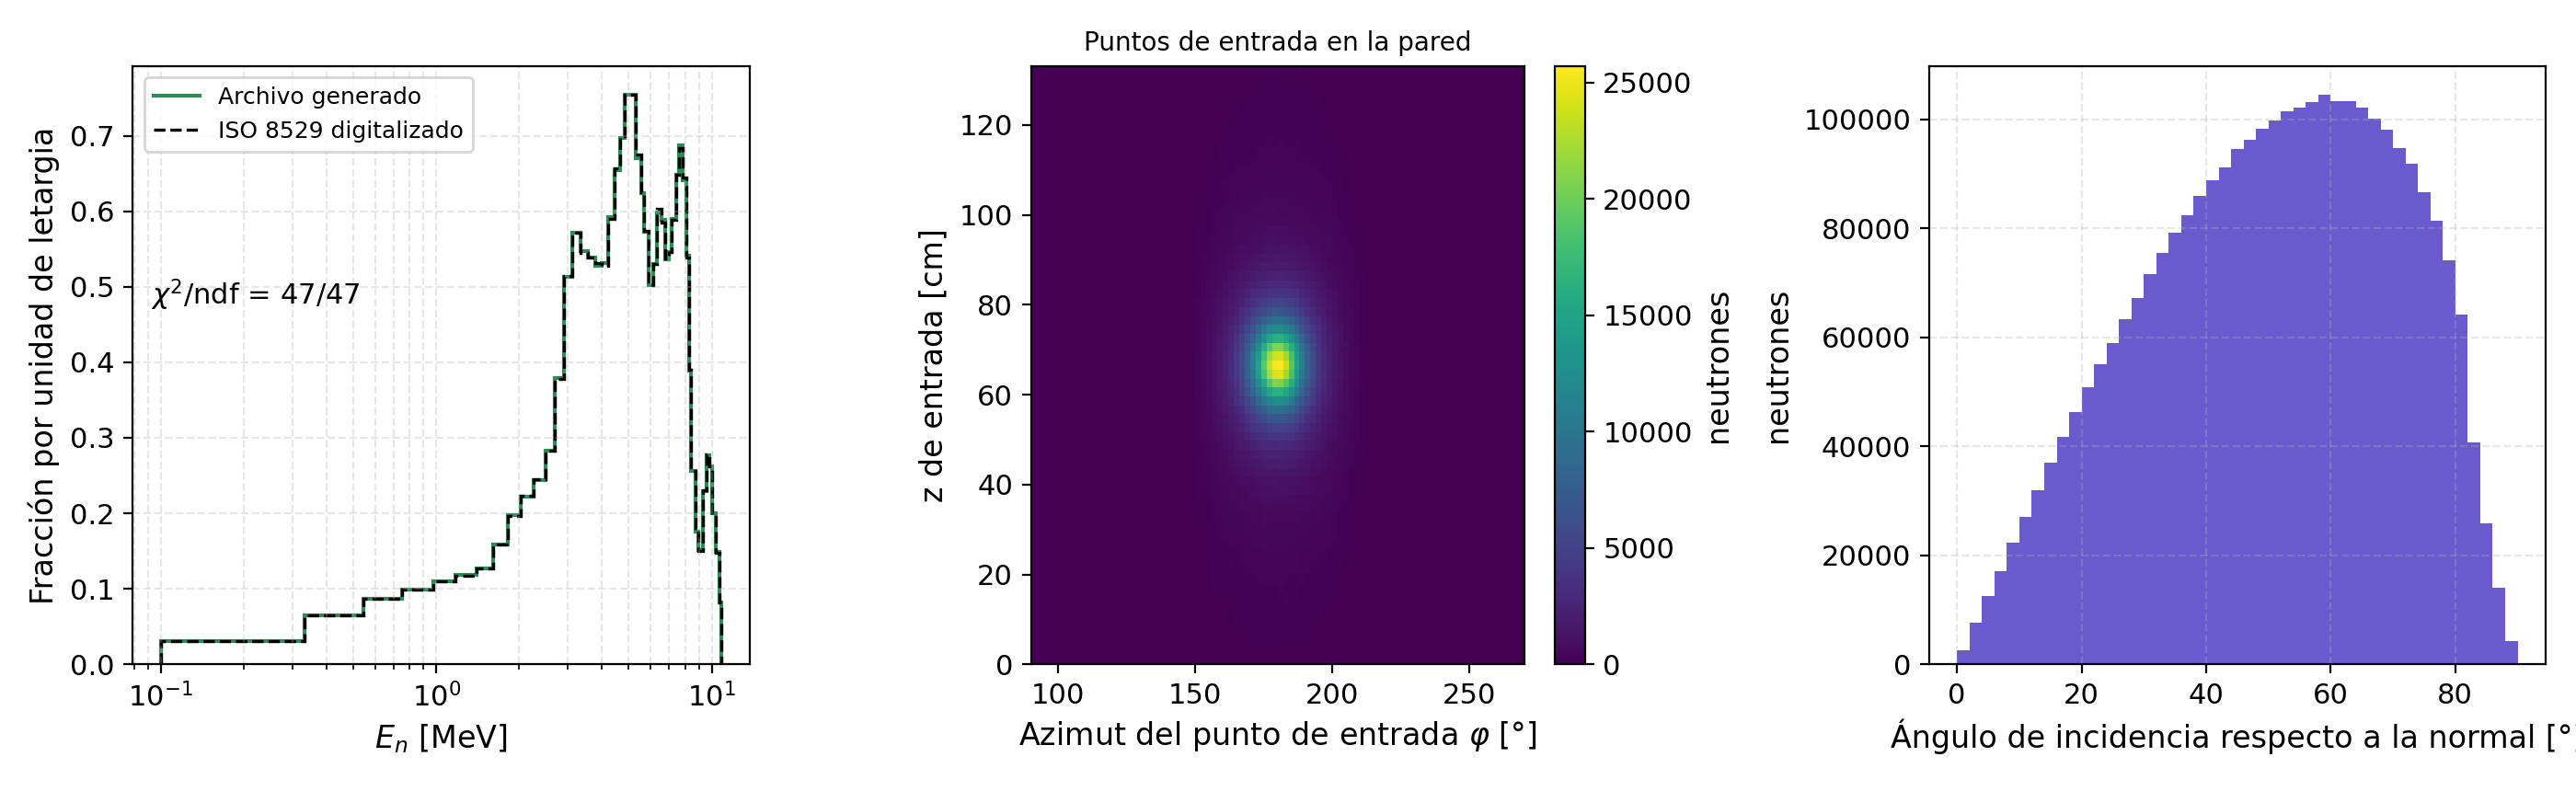

In [16]:
from IPython.display import Image
Image('figuras/fig11_validacion_irradiacion.png', width=780)

## 7. Montaje blindado: haz, halo y fondo
Caja de polietileno con canal de 3 cm × 30 cm y 10 cm de plomo pegado al tanque (fuente a 40 cm de la pared). Haz del canal: semiángulo 2.86°, 0.062 % de la emisión, mancha de 4 cm (12.6 cm²). `scripts/blindaje_fuga.py` estima por atenuación entre 4×10⁴ y 7.5×10⁵ neutrones rápidos al tanque, en su mayoría fuga por el polietileno.

Modelo adoptado por el autor (`scripts/generar_irradiacion_compuesta.py`), como fracción de lo que entra al tanque: **haz** 35 % (ISO 8529, cono de 2.86°), **halo** 45 % (0.5 eV–100 keV, 1/E, cara del plomo, 0–90° ley del coseno), **fondo** 20 % (1e-4–0.5 eV, maxwelliano kT = 25.3 meV, plano 96×133 cm, hemisferio isótropo). Normalización: haz = Q·Ω/4π·0.313·300 s = 1.30×10⁵, total = haz/0.35 = **373 272 neutrones** en 5 min.

In [17]:
runpy.run_path('scripts/blindaje_fuga.py', run_name='__main__');

{
 "Q_n_s": 2220000.0,
 "tiempo_s": 300.0,
 "fraccion_geom_hacia_tanque": 0.1511166,
 "fraccion_4pi_por_camino": {
  "canal": 0.00062105,
  "PE+Pb": 0.097256475,
  "solo_PE": 0.053239075
 },
 "no_colisionados": {
  "canal": {
   "n_por_s": 112.99656820473197,
   "n_5min": 33898.970461419594
  },
  "PE+Pb": {
   "n_por_s": 14.189627866568872,
   "n_5min": 4256.888359970661
  },
  "solo_PE": {
   "n_por_s": 20.19045071729509,
   "n_5min": 6057.135215188527
  },
  "total_n_5min": 44212.994036578784
 },
 "remocion": {
  "canal": {
   "n_por_s": 431.9000629987584,
   "n_5min": 129570.01889962752
  },
  "PE+Pb": {
   "n_por_s": 1170.7253949580675,
   "n_5min": 351217.61848742026
  },
  "solo_PE": {
   "n_por_s": 896.4138712404978,
   "n_5min": 268924.1613721493
  },
  "total_n_5min": 749711.7987591971
 }
}


In [18]:
import json
r = json.load(open('resultados/Irradiacion-AmBe-blindada-1Ci-300s/resumen.json'))
r['componentes']

{'haz': {'neutrones': 130711,
  'fraccion': 0.3501762789601149,
  'aceptacion_geometrica': 1.0,
  'E_media_MeV': 4.208540685630515,
  'E_mediana_MeV': 4.044637117952992,
  'E_min_MeV': 0.10002331198896489,
  'E_max_MeV': 10.838907833081525},
 'halo': {'neutrones': 167963,
  'fraccion': 0.44997481729141214,
  'aceptacion_geometrica': 0.7115257526955341,
  'E_media_MeV': 0.008147421104854103,
  'E_mediana_MeV': 0.00022168566001955778,
  'E_min_MeV': 5.000426629767129e-07,
  'E_max_MeV': 0.09999697625847916},
 'fondo': {'neutrones': 74598,
  'fraccion': 0.19984890374847297,
  'aceptacion_geometrica': 0.6740495723745945,
  'E_media_MeV': 5.045038427534727e-08,
  'E_mediana_MeV': 4.238067582081028e-08,
  'E_min_MeV': 2.440171958714142e-10,
  'E_max_MeV': 3.622076537328237e-07}}

In [19]:
runpy.run_path('scripts/validar_irradiacion_compuesta.py', run_name='__main__');

{
 "archivo": "373272N-Irradiacion-AmBe-blindada-1Ci-300s.txt",
 "neutrones": 373272,
 "todos_entran": true,
 "componentes_coinciden": true,
 "energia_coincide_rel": 1.1671892584934683e-06,
 "haz (ISO 8529)": {
  "n": 130711,
  "pct": 35.01762789601149,
  "E_media_eV": 4208540.683064406,
  "E_min_eV": 100023.33387318783,
  "E_max_eV": 10838906.468247522,
  "angulo_medio_eje_x_deg": 1.9084078394743131
 },
 "halo (0.5 eV–100 keV)": {
  "n": 167963,
  "pct": 44.997481729141214,
  "E_media_eV": 8147.421131748563,
  "E_min_eV": 0.5000427892936377,
  "E_max_eV": 99996.96468283045,
  "angulo_medio_eje_x_deg": 42.999886984538676
 },
 "fondo (1e-4–0.5 eV)": {
  "n": 74598,
  "pct": 19.984890374847296,
  "E_media_eV": 0.05045038422893046,
  "E_min_eV": 0.00024401716814116128,
  "E_max_eV": 0.36220772087889047,
  "angulo_medio_eje_x_deg": 52.91824881706471
 }
}


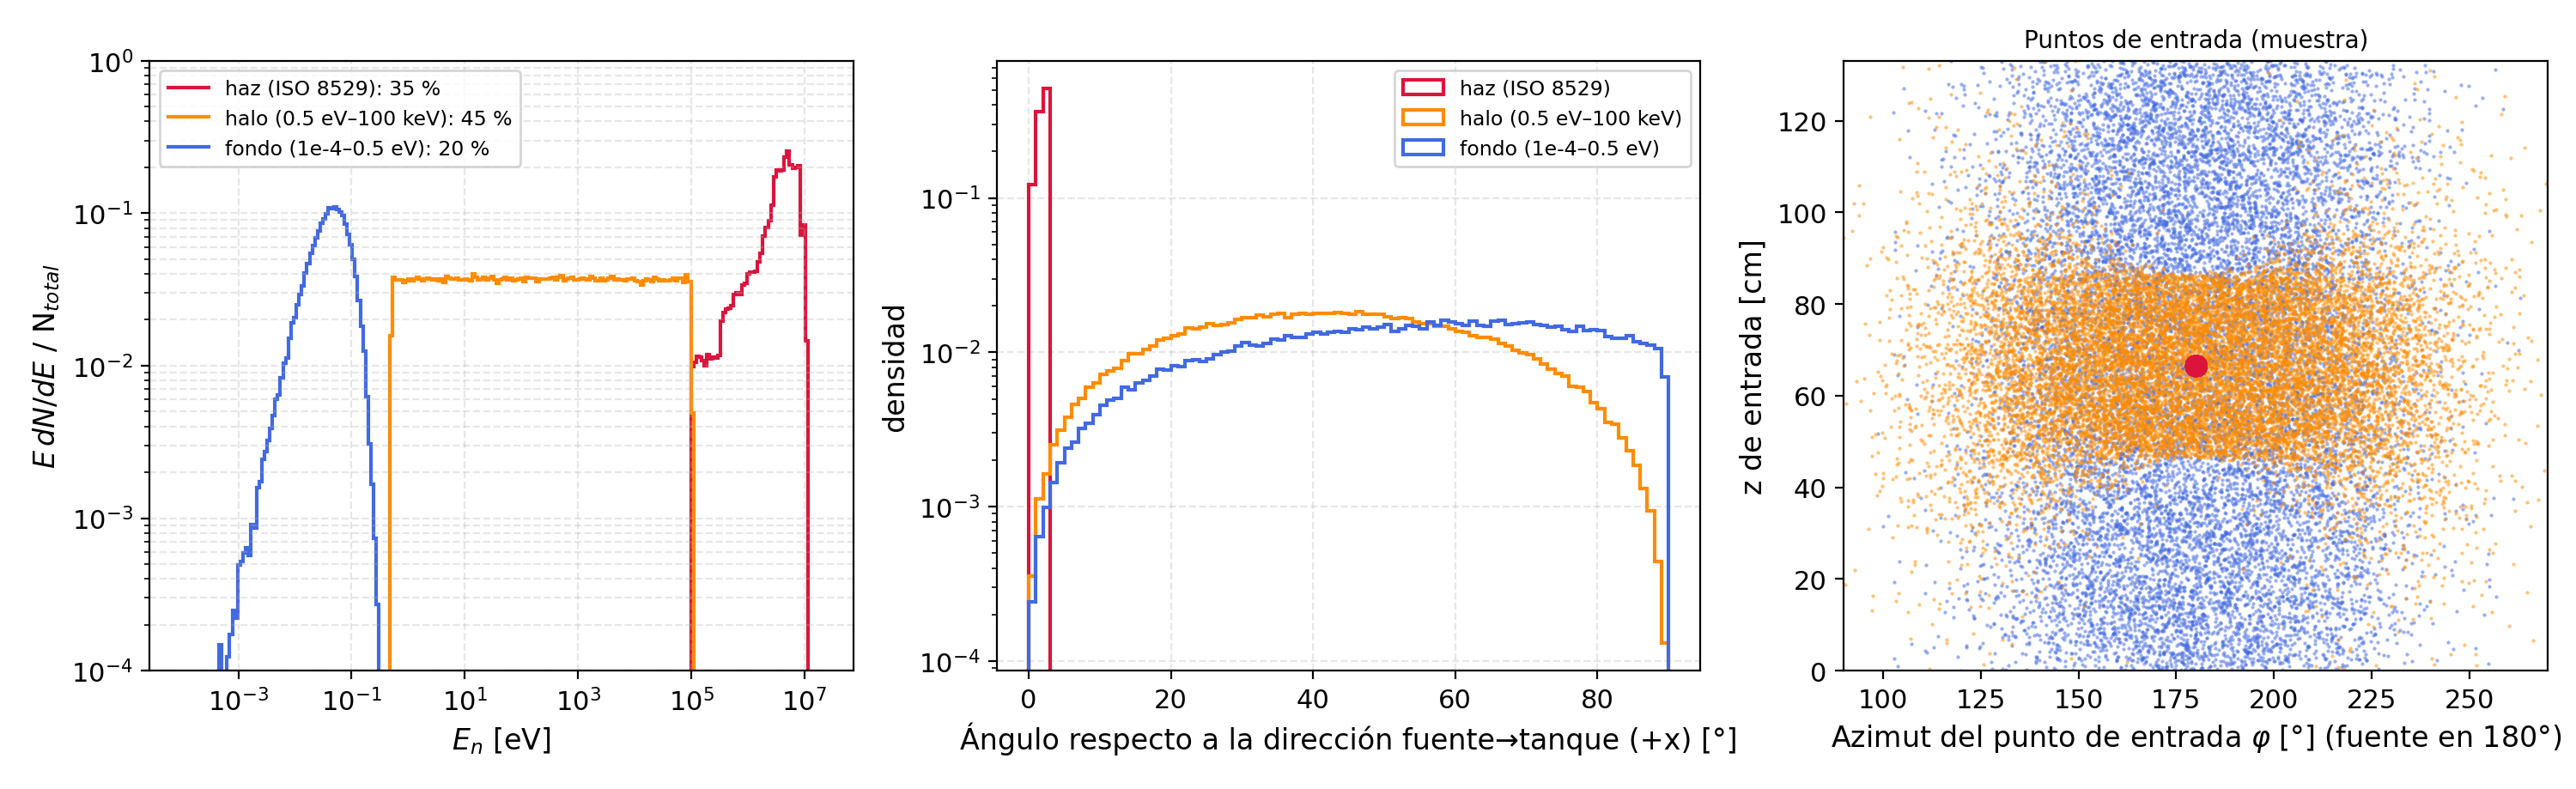

In [20]:
from IPython.display import Image
Image('figuras/fig12_irradiacion_compuesta.png', width=780)

## 8. Conclusiones
1. Formato y conversión $T\to p$ correctos.
2. El espectro digitalizado limpio es un Am-Be realista ($\langle E\rangle$ 4.15 vs 4.16 MeV ISO).
3. La fuente original lo distorsiona (densidad de puntos, 28 espurios, 437 líneas) y está ordenada.
4. Las curvas IAEA/ISO de la carpeta no son referencias reales; la segunda digitalización tiene el eje $y$ invertido.
5. Usar `resultados/Fuente-AmBe241-corregida-1637458n.txt` ($\chi^2$/ndf = 218/214) y declarar procedencia y geometría de emisión.\n6. Para irradiar el tanque: `resultados/Irradiacion-AmBe-1Ci-300s-d10cm/` (espectro ISO 8529, 1 Ci, 5 min, 10 cm). Simular una fracción de las partes y escalar por $N_{tanque}/N_{simulados}$.\n7. Montaje blindado (haz/halo/fondo 35/45/20 %): `resultados/Irradiacion-AmBe-blindada-1Ci-300s/` con 373 272 neutrones, una sola corrida de MEIGA.